In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
import seaborn as sns

In [39]:
washer_data= pd.read_csv("DATA_SET\Washer Data.csv")
washer_data.head(10)
df= washer_data.copy()

In [40]:
df.head(20)

,Sample No,Reading_Person,External Diameter,Internal Dismeter,Thickness,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,SAMPLE-1,Reading_N,39.96,20.48,2.012,NaN,NaN,NaN,NaN
1,SAMPLE-1,Reading_A,39.94,20.42,2.025,NaN,NaN,NaN,NaN
2,SAMPLE-1,Reading_M,39.99,20.46,2.018,NaN,NaN,NaN,NaN
3,SAMPLE-2,Reading_N,39.91,20.55,2.045,NaN,NaN,NaN,NaN
4,SAMPLE-2,Reading_A,39.97,20.35,2.040,NaN,NaN,NaN,NaN
5,SAMPLE-2,Reading_M,39.98,20.43,2.038,NaN,NaN,NaN,NaN
6,SAMPLE-3,Reading_N,39.88,20.52,2.051,NaN,NaN,NaN,NaN
7,SAMPLE-3,Reading_A,39.92,20.61,2.048,NaN,NaN,NaN,NaN
8,SAMPLE-3,Reading_M,39.97,20.48,2.050,NaN,NaN,NaN,NaN
9,SAMPLE-4,Reading_N,39.95,20.38,1.985,NaN,NaN,NaN,NaN


In [41]:
# if column Sample No is Nan the replace it with the previous not NaN value
df["Sample No"] = df["Sample No"].ffill()
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sample No          305 non-null    str    
 1   Reading_Person     300 non-null    str    
 2   External Diameter  300 non-null    float64
 3   Internal Dismeter  300 non-null    float64
 4   Thickness          300 non-null    float64
 5   Unnamed: 5         0 non-null      float64
 6   Unnamed: 6         0 non-null      float64
 7   Unnamed: 7         0 non-null      float64
 8   Unnamed: 8         0 non-null      float64
dtypes: float64(7), str(2)
memory usage: 21.6 KB


In [ ]:

# drop rows from 300
df.drop(df.index[300:], inplace=True)
df.drop(['Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8'], axis=1, inplace=True)
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sample No          300 non-null    str    
 1   Reading_Person     300 non-null    str    
 2   External Diameter  300 non-null    float64
 3   Internal Dismeter  300 non-null    float64
 4   Thickness          300 non-null    float64
dtypes: float64(3), str(2)
memory usage: 11.8 KB


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sample No          300 non-null    str    
 1   Reading_Person     300 non-null    str    
 2   External Diameter  300 non-null    float64
 3   Internal Dismeter  300 non-null    float64
 4   Thickness          300 non-null    float64
dtypes: float64(3), str(2)
memory usage: 11.8 KB


In [47]:
df.head(10)

,Sample No,Reading_Person,External Diameter,Internal Dismeter,Thickness
0,SAMPLE-1,Reading_N,39.96,20.48,2.012
1,SAMPLE-1,Reading_A,39.94,20.42,2.025
2,SAMPLE-1,Reading_M,39.99,20.46,2.018
3,SAMPLE-2,Reading_N,39.91,20.55,2.045
4,SAMPLE-2,Reading_A,39.97,20.35,2.040
5,SAMPLE-2,Reading_M,39.98,20.43,2.038
6,SAMPLE-3,Reading_N,39.88,20.52,2.051
7,SAMPLE-3,Reading_A,39.92,20.61,2.048
8,SAMPLE-3,Reading_M,39.97,20.48,2.050
9,SAMPLE-4,Reading_N,39.95,20.38,1.985


In [53]:
# in Reading_Person replace "Reading_N" by "Neeloptal"
df['Reading_Person'] = df['Reading_Person'].replace('Reading_N', 'Neeloptal')
df['Reading_Person'] = df['Reading_Person'].replace('Reading_A', 'Anush')
df['Reading_Person'] = df['Reading_Person'].replace('Reading_M', 'Mayukh')


In [63]:
# replace column name 
df = df.rename(columns={'External Diameter': 'External_Diameter', 'Internal Dismeter': 'Internal_Diameter', 'Thickness': 'Thickness', 'Sample No': 'Sample_No'})
df

,Sample_No,Reading_Person,External_Diameter,Internal_Diameter,Thickness
0,SAMPLE-1,Neeloptal,39.96,20.48,2.012
1,SAMPLE-1,Anush,39.94,20.42,2.025
2,SAMPLE-1,Mayukh,39.99,20.46,2.018
3,SAMPLE-2,Neeloptal,39.91,20.55,2.045
4,SAMPLE-2,Anush,39.97,20.35,2.040
...,...,...,...,...,...
295,SAMPLE-99,Anush,39.96,20.48,2.065
296,SAMPLE-99,Mayukh,39.99,20.47,2.062
297,SAMPLE-100,Neeloptal,39.90,20.48,2.015
298,SAMPLE-100,Anush,39.95,20.46,2.012


In [69]:
# find mean External Diameter and Internal Diameter for each Sample No and create a new dataframe with Sample No, mean External Diameter and mean Internal Diameter, mean Thickness
df_grouped = df.groupby('Sample_No')[['External_Diameter', 'Internal_Diameter', "Thickness"]].mean()
df_grouped = df_grouped.reset_index()
df_grouped

,Sample_No,External_Diameter,Internal_Diameter,Thickness
0,SAMPLE-1,39.963333,20.453333,2.018333
1,SAMPLE-10,39.970000,20.436667,2.205667
2,SAMPLE-100,39.940000,20.476667,2.012333
3,SAMPLE-11,39.956667,20.493333,2.043333
4,SAMPLE-12,39.956667,20.536667,2.028000
...,...,...,...,...
95,SAMPLE-95,39.943333,20.480000,2.022333
96,SAMPLE-96,39.960000,20.463333,2.007667
97,SAMPLE-97,39.933333,20.513333,2.050000
98,SAMPLE-98,39.950000,20.473333,1.980000


In [74]:
df_grouped = df_grouped.rename(columns={'External_Diameter': 'Mean_External_Diameter', 'Internal_Diameter': 'Mean_Internal_Diameter', 'Thickness': 'Mean_Thickness'})
df_grouped


,Sample_No,Mean_External_Diameter,Mean_Internal_Diameter,Mean_Thickness
0,SAMPLE-1,39.963333,20.453333,2.018333
1,SAMPLE-10,39.970000,20.436667,2.205667
2,SAMPLE-100,39.940000,20.476667,2.012333
3,SAMPLE-11,39.956667,20.493333,2.043333
4,SAMPLE-12,39.956667,20.536667,2.028000
...,...,...,...,...
95,SAMPLE-95,39.943333,20.480000,2.022333
96,SAMPLE-96,39.960000,20.463333,2.007667
97,SAMPLE-97,39.933333,20.513333,2.050000
98,SAMPLE-98,39.950000,20.473333,1.980000


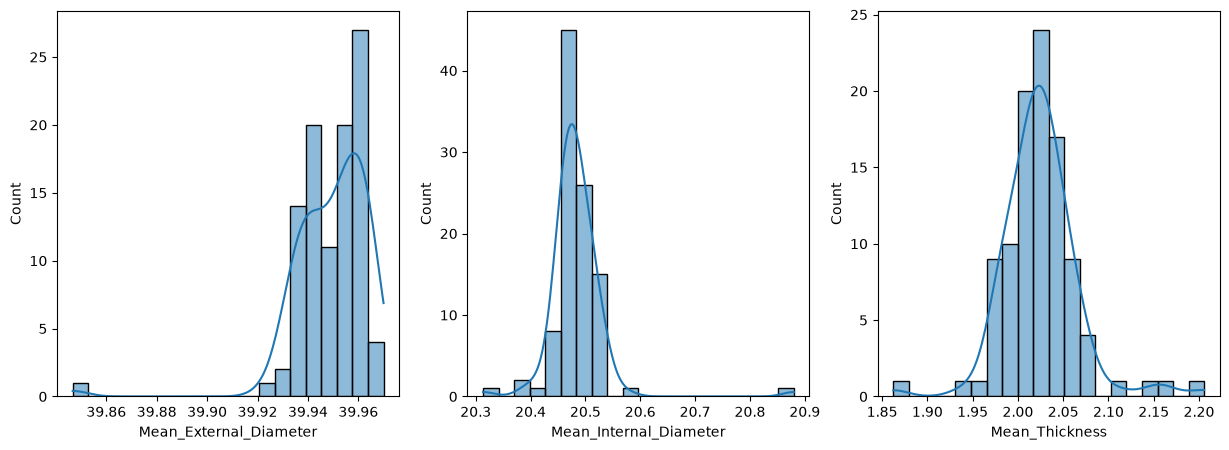

In [81]:
# plot histgram of Mean_External_Diameter, Mean_Internal_Diameter, Mean_Thickness with kde=True and bins=20
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df_grouped['Mean_External_Diameter'], kde=True, bins=20)

plt.subplot(1, 3, 2)
sns.histplot(df_grouped['Mean_Internal_Diameter'], kde=True, bins=20)

plt.subplot(1, 3, 3)
sns.histplot(df_grouped['Mean_Thickness'], kde=True, bins=20)

plt.show()


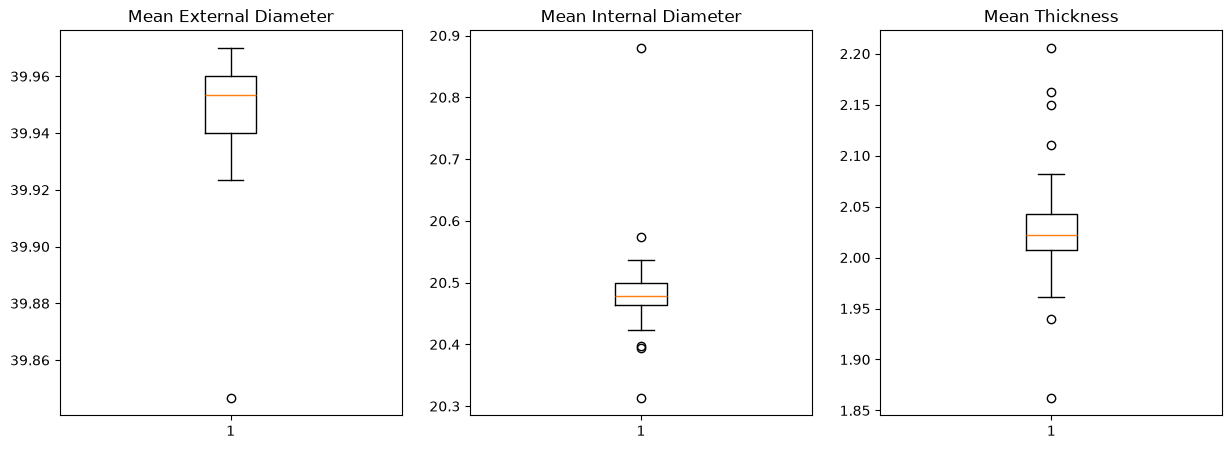

In [82]:
# find boxplot of Mean_External_Diameter, Mean_Internal_Diameter, Mean_Thickness
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.boxplot(df_grouped['Mean_External_Diameter'])
plt.title('Mean External Diameter')

plt.subplot(1, 3, 2)
plt.boxplot(df_grouped['Mean_Internal_Diameter'])
plt.title('Mean Internal Diameter')

plt.subplot(1, 3, 3)
plt.boxplot(df_grouped['Mean_Thickness'])
plt.title('Mean Thickness')

plt.show()

In [83]:
df_grouped.describe()

,Mean_External_Diameter,Mean_Internal_Diameter,Mean_Thickness
count,100.000000,100.000000,100.000000
mean,39.949400,20.483433,2.024727
std,0.015238,0.052009,0.041950
min,39.846667,20.313333,1.862333
25%,39.940000,20.463333,2.007667
50%,39.953333,20.478333,2.022333
75%,39.960000,20.500000,2.042333
max,39.970000,20.880000,2.205667


In [88]:
# find skewness, kurtosis of Mean_External_Diameter, Mean_Internal_Diameter, Mean_Thickness
print("Skewness:")
print(df_grouped['Mean_External_Diameter'].skew())
print(df_grouped['Mean_Internal_Diameter'].skew())
print(df_grouped['Mean_Thickness'].skew())

print("Kurtosis:")
print(df_grouped['Mean_External_Diameter'].kurtosis())
print(df_grouped['Mean_Internal_Diameter'].kurtosis())
print(df_grouped['Mean_Thickness'].kurtosis())

Skewness:
-3.1669317161084063
4.177326883230758
0.7900759847910492
Kurtosis:
19.648739288074285
34.81874195429618
5.878504515855967
